# C. LSTM — 녹화 하나 빼기 21-fold (분류 비교용)

- 할 일: 같은 21-fold에서 LSTM의 재질 8종 분류 성능을 내서 MiniRocket·FCN·B 고전 모델과 비교
- 이 노트북의 역할
  - FCN(합성곱: 짧은 구간 패턴을 필터로 찾음)과 다른 방식인 순환 신경망(시간 순서대로 한 스텝씩 읽음) 비교
  - 임베딩은 D·E에 넘기지 않음 (전달용은 FCN). 그래서 재질 하나 빼기 147-fold는 돌리지 않음
- 평가: `splits/folds.json`의 21-fold, 21개 fold 예측을 모은 뒤 `evaluate()` 한 번 (팀 공통 규칙)
- 순서: 준비 → 모델 → 1 epoch 시간 → 튜닝(epoch 수) → 21-fold → 비교 → 진행 기록
- 끊겨도 이어서 돌 수 있게 튜닝 기록·설정은 드라이브에 저장

## 0. 환경 준비

- 레포 받기, 패키지 설치, 데이터 준비(드라이브 사본 → 없으면 Zenodo), 드라이브 연결
- FCN 노트북과 같은 셀. 드라이브 `ML-imu/data_cache/`에 데이터 사본이 있으면 Zenodo를 거치지 않음

In [1]:
import os
import sys
import json
import time
import shutil
import subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not Path("/content/ML-imu").exists():
        !git clone -q https://github.com/ekgP525/ML-imu.git /content/ML-imu
    os.chdir("/content/ML-imu")
    !pip install -q -r requirements.txt

    # 데이터 준비: ① 드라이브 사본 → 없으면 ② Zenodo에서 파일 직접 받기
    # (팀 download.py는 Zenodo 응답이 30초를 넘으면 실패해서, 기다리는 시간을 늘리고 재시도한다)
    from google.colab import drive
    drive.mount("/content/drive")
    CACHE = Path("/content/drive/MyDrive/ML-imu/data_cache")
    CACHE.mkdir(parents=True, exist_ok=True)
    DATA_FILES = {"X_data.npy": 78090368, "label.npy": 61136,
                  "groups.npy": 61136, "details.csv": 128466}   # 파일 이름: 정상 크기(바이트)
    ok = lambda f, size: f.exists() and f.stat().st_size == size
    for name, size in DATA_FILES.items():
        dest = Path("data") / name
        if ok(dest, size):
            continue
        if ok(CACHE / name, size):
            shutil.copy(CACHE / name, dest)
            print("드라이브 사본 사용:", name)
            continue
        url = f"https://zenodo.org/records/2653918/files/{name}?download=1"
        subprocess.run(["wget", "-q", "--tries=5", "--timeout=120", "-O", str(dest), url])
        if not ok(dest, size):
            raise RuntimeError(f"{name} 다운로드 실패 (Zenodo가 느림) → 이 셀을 다시 실행하세요")
        shutil.copy(dest, CACHE / name)
        print("Zenodo에서 받음 + 드라이브에 사본 저장:", name)
    print("데이터 준비 완료")

ROOT = Path.cwd()
while not (ROOT / "src").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.append(str(ROOT / "src"))
print("레포 위치:", ROOT)

Mounted at /content/drive
드라이브 사본 사용: X_data.npy
드라이브 사본 사용: label.npy
드라이브 사본 사용: groups.npy
드라이브 사본 사용: details.csv
데이터 준비 완료
레포 위치: /content/ML-imu


In [2]:
OUT_DIR = Path("/content/drive/MyDrive/ML-imu/lstm") if IN_COLAB else ROOT / "lstm_out"
OUT_DIR.mkdir(parents=True, exist_ok=True)
print("저장 위치:", OUT_DIR, "(튜닝 기록·설정·학습 기록, 몇 MB 이하)")

저장 위치: /content/drive/MyDrive/ML-imu/lstm (튜닝 기록·설정·학습 기록, 몇 MB 이하)


## 1. 데이터와 분할

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import f1_score, confusion_matrix

from recordings import load_dataset, CLASSES
from splits import load_folds, fold_indices, inner_val_recordings
from preprocess import normalize
from evaluate import evaluate, log_result, to_mode

SEED = 42
torch.backends.cudnn.deterministic = True    # 같은 seed면 같은 결과가 나오게
torch.backends.cudnn.benchmark = False
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU 없음 → 런타임 → 런타임 유형 변경 → GPU 로 바꾸고 다시 실행")

X, y, rec = load_dataset(str(ROOT / "data"))
folds = load_folds()
print("X", X.shape, "| 녹화 하나 빼기", len(folds), "fold")

GPU: Tesla T4
X (7626, 128, 6) | 녹화 하나 빼기 21 fold


## 2. 모델

```
구간 128스텝 × 6채널 → LSTM 2층(은닉 128) → 마지막 스텝의 은닉 상태(128) → 선형층 → 재질별 점수(logits)
```

- LSTM: 한 스텝(6개 값)씩 순서대로 읽으면서 기억(은닉 상태)을 갱신. 128스텝을 다 읽은 뒤의 기억이 구간 요약
- FCN과 맞춘 것: 은닉 크기 128(= FCN 임베딩 128차원), Adam lr 1e-3, 배치 64, seed 42, dropout 없음
- LSTM에만 추가: 기울기 크기 제한(gradient clipping, 최대 노름 1.0). 순환 신경망은 긴 순서에서 기울기가 갑자기 커져 학습이 튀는 일이 있어서 흔히 씀
- 단방향 LSTM (양방향 BiLSTM은 이번 범위 밖)

In [4]:
HIDDEN = 128
LAYERS = 2
LR = 1e-3
BATCH = 64
CLIP = 1.0


class LSTMClassifier(nn.Module):
    def __init__(self, in_ch, n_classes):
        super().__init__()
        self.lstm = nn.LSTM(in_ch, HIDDEN, num_layers=LAYERS, batch_first=True)
        self.head = nn.Linear(HIDDEN, n_classes)

    def forward(self, x):                   # x: (배치, 128스텝, 6채널)
        out, _ = self.lstm(x)               # out: (배치, 128, 128) = 스텝마다의 은닉 상태
        z = out[:, -1]                      # 마지막 스텝의 은닉 상태 → (배치, 128)
        return z, self.head(z)              # 요약 벡터, logits


m = LSTMClassifier(6, 8)
print(m)
print("파라미터 수:", sum(p.numel() for p in m.parameters()))

LSTMClassifier(
  (lstm): LSTM(6, 128, num_layers=2, batch_first=True)
  (head): Linear(in_features=128, out_features=8, bias=True)
)
파라미터 수: 202760


### 학습 함수

- FCN 노트북과 같은 구조 (center loss 부분만 없음)
- 입력 모양: LSTM은 (배치, 시간, 채널) 순서를 받으므로 데이터 모양 (N, 128, 6) 그대로 사용

In [5]:
def to_input(x):
    return np.ascontiguousarray(x, dtype=np.float32)


@torch.no_grad()
def predict(model, x, bs=1024):
    model.eval()
    ls = []
    for b in range(0, len(x), bs):
        _, l = model(torch.from_numpy(x[b:b + bs]).to(DEVICE))
        ls.append(l.cpu())
    return torch.cat(ls).numpy()


def train_model(x_tr, y_tr, classes, epochs, x_val=None, y_val=None):
    torch.manual_seed(SEED)
    lookup = {c: i for i, c in enumerate(classes)}
    xt = torch.from_numpy(x_tr).to(DEVICE)
    yt = torch.tensor([lookup[c] for c in y_tr], device=DEVICE)
    model = LSTMClassifier(xt.shape[2], len(classes)).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    gen = torch.Generator().manual_seed(SEED)
    hist = []
    for ep in range(1, epochs + 1):
        t0 = time.perf_counter()
        model.train()
        perm = torch.randperm(len(xt), generator=gen).to(DEVICE)
        sum_ce = torch.zeros((), device=DEVICE)
        for b in range(0, len(xt), BATCH):
            idx = perm[b:b + BATCH]
            _, logits = model(xt[idx])
            ce = F.cross_entropy(logits, yt[idx])
            opt.zero_grad()
            ce.backward()
            nn.utils.clip_grad_norm_(model.parameters(), CLIP)
            opt.step()
            sum_ce += ce.detach() * len(idx)
        if DEVICE == "cuda":
            torch.cuda.synchronize()
        row = {"epoch": ep, "sec": time.perf_counter() - t0, "train_ce": sum_ce.item() / len(xt)}
        if x_val is not None:
            pred = np.array(classes)[predict(model, x_val).argmax(1)]
            row["val_macro_f1"] = f1_score(y_val, pred, labels=np.unique(y_val), average="macro")
            row["val_acc"] = float(np.mean(pred == y_val))
        hist.append(row)
    return model, pd.DataFrame(hist)


LOG_PATH = OUT_DIR / "train_log.csv"


def log_train(**row):
    """학습 1회마다 드라이브의 train_log.csv에 한 줄 추가 (진행 기록용: 시간·횟수·loss)."""
    row = {"date": pd.Timestamp.now().strftime("%Y-%m-%d %H:%M"), **row}
    pd.DataFrame([row]).to_csv(LOG_PATH, mode="a", header=not LOG_PATH.exists(), index=False)

## 3. 1 epoch 시간 재기

- fold 0에서 4 epoch만 돌려 시간을 재고 전체 예상 시간을 출력 (첫 epoch는 준비 시간이 섞여서 빼고 평균)
- LSTM은 128스텝을 순서대로 계산해야 해서 FCN보다 느림

In [6]:
MAX_EPOCHS = 100
TUNE_FOLDS = list(range(0, 21, 4))    # FCN과 같은 6개 fold(0, 4, 8, 12, 16, 20)

tr, te = fold_indices(folds[0], rec)
x_tr, stats = normalize(X[tr])
_, h = train_model(to_input(x_tr), y[tr], CLASSES, epochs=4)
SEC_PER_EPOCH = h.sec.iloc[1:].mean()
print(h.round(3).to_string(index=False))
print(f"\n1 epoch ≈ {SEC_PER_EPOCH:.2f}초 (학습 구간 {len(tr)}개, 배치 {BATCH})")
for name, n in [("튜닝", len(TUNE_FOLDS)), ("분류 21-fold", len(folds))]:
    print(f"{name:<12} 학습 {n:2d}번 × 최대 {MAX_EPOCHS} epoch ≈ 최대 {n * MAX_EPOCHS * SEC_PER_EPOCH / 3600:.1f}시간")

 epoch   sec  train_ce
     1 2.767     1.870
     2 0.735     1.569
     3 0.736     1.474
     4 0.738     1.458

1 epoch ≈ 0.74초 (학습 구간 7323개, 배치 64)
튜닝           학습  6번 × 최대 100 epoch ≈ 최대 0.1시간
분류 21-fold   학습 21번 × 최대 100 epoch ≈ 최대 0.4시간


## 4. 튜닝: epoch 수 고르기

- FCN과 같은 방식: 학습 녹화 안에서 재질마다 녹화를 검증용으로 떼고(`inner_val_recordings`), 나머지로 학습하며 epoch마다 검증 macro-F1 기록
- 시험 녹화는 보지 않음
- 6개 fold 평균 곡선(5 epoch 이동평균)이 가장 높은 epoch를 21-fold에 사용
- 한계(FCN과 같음): 고른 epoch를 21개 fold에 같이 씀
- 끝난 fold는 `lstm_tuning.csv`를 보고 건너뜀

In [7]:
TUNE_PATH = OUT_DIR / "lstm_tuning.csv"
done = set()
if TUNE_PATH.exists():
    done = set(pd.read_csv(TUNE_PATH)["fold"])
    print("이미 끝난 튜닝 fold:", sorted(done))

for fid in TUNE_FOLDS:
    if fid in done:
        continue
    fold = folds[fid]
    val_recs = inner_val_recordings(fold["train"], y, rec)
    fit_recs = [r for r in fold["train"] if r not in val_recs]
    fit = np.where(np.isin(rec, fit_recs))[0]
    val = np.where(np.isin(rec, val_recs))[0]
    x_fit, stats = normalize(X[fit])
    x_val = normalize(X[val], stats)
    t0 = time.perf_counter()
    _, h = train_model(to_input(x_fit), y[fit], CLASSES, MAX_EPOCHS, to_input(x_val), y[val])
    h["fold"] = fid
    h.to_csv(TUNE_PATH, mode="a", header=not TUNE_PATH.exists(), index=False)
    log_train(model="lstm-tuning", split="inner-validation", fold=fid, n_train=len(fit),
              epochs=MAX_EPOCHS, sec=round(time.perf_counter() - t0, 1),
              sec_per_epoch=round(h.sec.mean(), 3), final_train_ce=round(h.train_ce.iloc[-1], 4))
    print(f"fold {fid:2d} | 검증 녹화 {val_recs} | 마지막 검증 macro-F1 "
          f"{h.val_macro_f1.iloc[-1]:.3f} | {time.perf_counter() - t0:.0f}초")

tune_df = pd.read_csv(TUNE_PATH)

fold  0 | 검증 녹화 [20, 19, 9, 13, 11, 17, 18] | 마지막 검증 macro-F1 0.349 | 56초
fold  4 | 검증 녹화 [20, 19, 9, 6, 13, 11, 17, 18] | 마지막 검증 macro-F1 0.316 | 56초
fold  8 | 검증 녹화 [20, 19, 9, 6, 13, 11, 17, 18] | 마지막 검증 macro-F1 0.323 | 55초
fold 12 | 검증 녹화 [20, 19, 9, 6, 13, 11, 17, 18] | 마지막 검증 macro-F1 0.328 | 53초
fold 16 | 검증 녹화 [20, 19, 9, 6, 13, 11, 17, 18] | 마지막 검증 macro-F1 0.362 | 53초
fold 20 | 검증 녹화 [15, 19, 9, 6, 13, 11, 17, 18] | 마지막 검증 macro-F1 0.307 | 54초


최고 검증 macro-F1 0.333 (epoch 74)
선택: {'lstm': {'epochs': 74}}


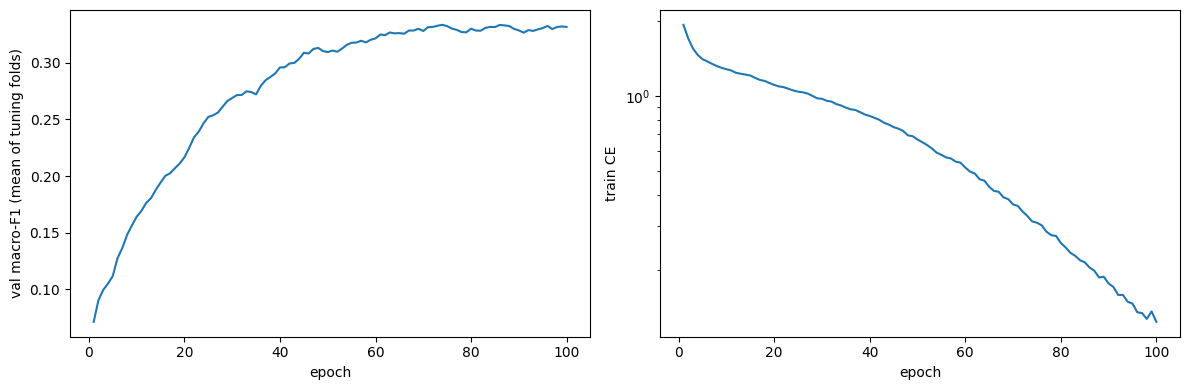

In [8]:
curve = tune_df.pivot_table(index="epoch", values="val_macro_f1", aggfunc="mean")["val_macro_f1"]
smooth = curve.rolling(5, min_periods=1).mean()
config = {"lstm": {"epochs": int(smooth.idxmax())}}
(OUT_DIR / "lstm_config.json").write_text(json.dumps(config, indent=2))
print(f"최고 검증 macro-F1 {smooth.max():.3f} (epoch {smooth.idxmax()})")
print("선택:", config)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(smooth.index, smooth.values)
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("val macro-F1 (mean of tuning folds)")
train_curve = tune_df.pivot_table(index="epoch", values="train_ce", aggfunc="mean")["train_ce"]
axes[1].plot(train_curve.index, train_curve.values)
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("train CE")
axes[1].set_yscale("log")
plt.tight_layout()
plt.show()

### 곡선 읽는 법

- 왼쪽(검증 macro-F1): 올라가다 평평해지는 지점이 적당한 epoch
- 오른쪽(학습 CE): 계속 내려가는데 검증은 그대로면 학습 녹화를 외우는 중
- 학습 CE가 거의 안 내려가면 LSTM이 128스텝을 제대로 못 배우는 것 → FCN과 비교할 때 이유로 적기

## 5. 분류: 녹화 하나 빼기 21-fold

- fold마다: 학습 녹화로 정규화 통계 계산 → 학습 → 시험 녹화 예측
- 21개 예측을 모아 `evaluate()` 한 번 → `results.csv`에 기록
- 끊기면 처음부터 다시 (21개를 모아서 채점하기 때문)

In [9]:
cfg = config["lstm"]
y_pred = np.empty(len(y), dtype=object)
rows = []
t_all = time.perf_counter()
for fold in folds:
    tr, te = fold_indices(fold, rec)
    x_tr, stats = normalize(X[tr])
    x_te = normalize(X[te], stats)
    t0 = time.perf_counter()
    model, h = train_model(to_input(x_tr), y[tr], CLASSES, cfg["epochs"])
    sec = time.perf_counter() - t0
    y_pred[te] = np.array(CLASSES)[predict(model, to_input(x_te)).argmax(1)]
    acc = float(np.mean(y_pred[te] == y[te]))
    wrong = pd.Series(y_pred[te][y_pred[te] != y[te]])
    rows.append({"fold": fold["fold"], "test_rec": fold["test"][0], "surface": y[te][0],
                 "segments": len(te), "accuracy": round(acc, 3),
                 "mostly_confused_with": wrong.mode().iloc[0] if len(wrong) else "-",
                 "sec": round(sec, 1)})
    log_train(model="lstm", split="leave-one-recording-out", fold=fold["fold"], n_train=len(tr),
              epochs=cfg["epochs"], sec=round(sec, 1), sec_per_epoch=round(h.sec.mean(), 3),
              final_train_ce=round(h.train_ce.iloc[-1], 4))
    print(f"fold {fold['fold']:2d} | 녹화 {fold['test'][0]:2d} {y[te][0]:<13} | 정확도 {acc:.3f} | {sec:5.1f}초")

assert not any(p is None for p in y_pred)
y_pred = y_pred.astype(str)
total = time.perf_counter() - t_all
per_fold = pd.DataFrame(rows)
print(f"\n전체 {total / 60:.1f}분")
per_fold

fold  0 | 녹화  0 hard_tiles    | 정확도 0.228 |  61.2초
fold  1 | 녹화  1 soft_pvc      | 정확도 0.343 |  60.6초
fold  2 | 녹화  2 soft_tiles    | 정확도 0.101 |  61.5초
fold  3 | 녹화  3 fine_concrete | 정확도 0.333 |  61.7초
fold  4 | 녹화  4 concrete      | 정확도 0.402 |  62.0초
fold  5 | 녹화  5 soft_pvc      | 정확도 0.012 |  60.4초
fold  6 | 녹화  6 hard_tiles    | 정확도 0.161 |  59.0초
fold  7 | 녹화  7 carpet        | 정확도 0.285 |  62.3초
fold  8 | 녹화  8 tiled         | 정확도 0.150 |  61.5초
fold  9 | 녹화  9 fine_concrete | 정확도 0.080 |  59.0초
fold 10 | 녹화 10 soft_pvc      | 정확도 0.316 |  62.6초
fold 11 | 녹화 11 soft_tiles    | 정확도 0.102 |  61.8초
fold 12 | 녹화 12 tiled         | 정확도 0.381 |  60.1초
fold 13 | 녹화 13 soft_pvc      | 정확도 0.404 |  61.4초
fold 14 | 녹화 14 wood          | 정확도 0.442 |  62.7초
fold 15 | 녹화 15 carpet        | 정확도 0.689 |  60.7초
fold 16 | 녹화 16 concrete      | 정확도 0.155 |  59.7초
fold 17 | 녹화 17 tiled         | 정확도 0.276 |  59.1초
fold 18 | 녹화 18 wood          | 정확도 0.173 |  56.0초
fold 19 | 녹화 19 concrete      |

,fold,test_rec,surface,segments,accuracy,mostly_confused_with,sec
0,0,0,hard_tiles,303,0.228,tiled,61.2
1,1,1,soft_pvc,362,0.343,wood,60.6
2,2,2,soft_tiles,287,0.101,soft_pvc,61.5
3,3,3,fine_concrete,243,0.333,concrete,61.7
4,4,4,concrete,219,0.402,soft_pvc,62.0
5,5,5,soft_pvc,404,0.012,soft_tiles,60.4
6,6,6,hard_tiles,576,0.161,tiled,59.0
7,7,7,carpet,172,0.285,wood,62.3
8,8,8,tiled,273,0.150,fine_concrete,61.5
9,9,9,fine_concrete,578,0.080,concrete,59.0


{'macro_f1': 0.2611, 'accuracy': 0.2675, 'mode_macro_f1': 0.6208} | 모드 정확도 0.6963
(모드 정확도 기준선: 전부 '딱딱한 바닥'이면 0.663)


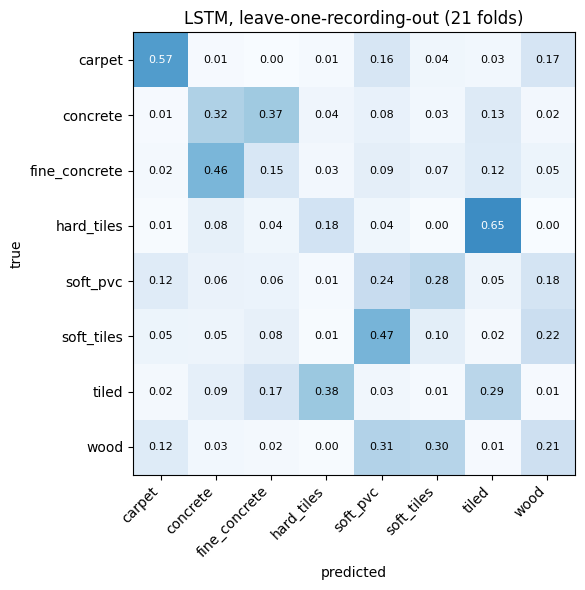

In [10]:
met = evaluate(y, y_pred)
mode_acc = float(np.mean(to_mode(y) == to_mode(y_pred)))
print({k: round(v, 4) for k, v in met.items()}, "| 모드 정확도", round(mode_acc, 4))
print("(모드 정확도 기준선: 전부 '딱딱한 바닥'이면 0.663)")

log_result("C", "lstm", met, setting="8class", fold="all",
           note=f"LSTM {LAYERS}x{HIDDEN} last-step, epochs={cfg['epochs']} batch={BATCH} lr={LR} clip={CLIP}, "
                f"6ch, total {total / 60:.1f}min")

cm = confusion_matrix(y, y_pred, labels=CLASSES, normalize="true")
fig, ax = plt.subplots(figsize=(7, 6))
ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(CLASSES)), CLASSES, rotation=45, ha="right")
ax.set_yticks(range(len(CLASSES)), CLASSES)
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if cm[i, j] > 0.5 else "black")
ax.set_xlabel("predicted")
ax.set_ylabel("true")
ax.set_title("LSTM, leave-one-recording-out (21 folds)")
plt.tight_layout()
plt.show()

## 6. 다른 모델과 비교

- Colab 레포의 `results.csv`는 GitHub에서 받은 시점의 내용 + 이번에 추가한 lstm 줄
- FCN 결과가 아직 GitHub에 없으면 표에 안 나옴 → FCN 노트북 결과와 직접 비교

In [11]:
res_csv = pd.read_csv(ROOT / "results" / "results.csv")
cols = ["owner", "model", "macro_f1", "accuracy", "mode_macro_f1"]
print(res_csv[res_csv.setting == "8class"][cols].to_string(index=False))
print("\n↑ 새로 추가된 lstm 줄을 로컬 results/results.csv 끝에 붙여 넣고 커밋")

owner         model  macro_f1  accuracy  mode_macro_f1
    B rule_baseline    0.3510    0.3732         0.6663
    C    minirocket    0.2571    0.2796         0.7163
    C           fcn    0.2887    0.3025         0.6983
    C    fcn-center    0.2816    0.3061         0.6880
    C          lstm    0.2611    0.2675         0.6208

↑ 새로 추가된 lstm 줄을 로컬 results/results.csv 끝에 붙여 넣고 커밋


## 7. 진행 기록 정리

In [12]:
log = pd.read_csv(LOG_PATH)
tbl = log.groupby(["model", "split"]).agg(
    runs=("fold", "size"),
    epochs=("epochs", "first"),
    sec_per_epoch=("sec_per_epoch", "mean"),
    sec_per_run=("sec", "mean"),
    total_min=("sec", lambda s: s.sum() / 60),
    final_train_ce=("final_train_ce", "mean"),
).round(3)
print(tbl.to_string())
print("\nGPU:", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU")

                                     runs  epochs  sec_per_epoch  sec_per_run  total_min  final_train_ce
model       split                                                                                       
lstm        leave-one-recording-out    21      74          0.820       60.700     21.245           0.182
lstm-tuning inner-validation            6     100          0.396       54.417      5.442           0.123

GPU: Tesla T4


### 진행 기록에 적을 것

- 모델 구조: LSTM 2층 은닉 128, 마지막 스텝 은닉 상태 → 선형층, gradient clipping 1.0
- 튜닝: 6 fold × 100 epoch, 고른 epoch와 최고 검증 macro-F1
- 위 표: 학습 횟수, 1 epoch 초, 1회 학습 시간, 총 시간, 최종 train CE
- 결과: macro-F1, 정확도, 모드 macro-F1, 모드 정확도 / MiniRocket·FCN·B 규칙 기준선과 비교
- 혼동행렬에서 FCN과 달라진 재질